In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_score
import pickle 
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [2]:
# Memuat dataset yang sudah rapi 
data = "data.csv"
df = pd.read_csv(data, index_col=0)
df['sex'] = df['sex'].replace({'Male' : 1,'Female': 0})
df['cp'] = df['cp'].replace({'typical angina' : 0, 'atypical angina' : 1, 'non-anginal pain' : 2, 'asymptomatic' : 3})
df['fbs'] = df['fbs'].replace({'No' : 0, 'Yes' : 1})
df['restecg'] = df['restecg'].replace({'probable or definite left ventricular hypertrophy':0,'normal':1,'ST-T Wave abnormal':2})
df['exang'] = df['exang'].replace({'No':0,'Yes':1})
df['slope'] = df['slope'].replace({'downsloping':0, 'flat':1,'upsloping':2})
df['thal'] = df['thal'].replace({'normal':1, 'fixed defect':2,'reversable defect':3})
df['ca'] = df['ca'].replace({'Number of major vessels: 0':0, 'Number of major vessels: 1':1,'Number of major vessels: 2':2, 'Number of major vessels: 3':3})
df['target'] = df['target'].replace({'No disease':0,'Disease':1})

# Variabel terpilih
df = df[['cp', 'thalach', 'slope', 'oldpeak', 'exang', 'ca', 'thal', 'sex', 'age', 'target']]

In [3]:
# Liat informasi dari dataset yang kita miliki
print(df.head())
print(df.info())

   cp  thalach  slope  oldpeak  exang  ca  thal  sex  age  target
0   0      168      2      1.0      0   2     3    1   52       0
1   0      155      0      3.1      1   0     3    1   53       0
2   0      125      0      2.6      1   0     3    1   70       0
3   0      161      2      0.0      0   1     3    1   61       0
4   0      106      1      1.9      0   3     2    0   62       0
<class 'pandas.core.frame.DataFrame'>
Index: 283 entries, 0 to 878
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   cp       283 non-null    int64  
 1   thalach  283 non-null    int64  
 2   slope    283 non-null    int64  
 3   oldpeak  283 non-null    float64
 4   exang    283 non-null    int64  
 5   ca       283 non-null    int64  
 6   thal     283 non-null    int64  
 7   sex      283 non-null    int64  
 8   age      283 non-null    int64  
 9   target   283 non-null    int64  
dtypes: float64(1), int64(9)
memory usage: 24.3 

In [4]:
# Pisahkan variabel X dan y
X = df.drop('target', axis=1)
y = df['target']

In [5]:
# Melihat kolom yang termasuk variable indepnden
X.head()

,cp,thalach,slope,oldpeak,exang,ca,thal,sex,age
0,0,168,2,1.0,0,2,3,1,52
1,0,155,0,3.1,1,0,3,1,53
2,0,125,0,2.6,1,0,3,1,70
3,0,161,2,0.0,0,1,3,1,61
4,0,106,1,1.9,0,3,2,0,62


In [6]:
# Melihat variabel dependen
y.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [7]:
# Buat scaling data dengan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
# Mendefinisikan pemisahan data
X_train, X_test, y_train, y_test = train_test_split(X_scaled , y, test_size=0.2, random_state=42)

# Menampilkan hasil pemisahan berdasarkan kolom dan baris
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(226, 9)
(57, 9)
(226,)
(57,)


In [9]:
# Menyiapkan libraries
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [10]:
# Modeling with Logistic Regression
clf = LogisticRegression(random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of Logistric Regression Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of Logistric Regression Classifier is  0.8421052631578947


In [11]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.81      0.82        26
           1       0.84      0.87      0.86        31

    accuracy                           0.84        57
   macro avg       0.84      0.84      0.84        57
weighted avg       0.84      0.84      0.84        57



In [12]:
# Modeling with Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of Decision Tree Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of Decision Tree Classifier is  0.7192982456140351


In [13]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.68      0.73      0.70        26
           1       0.76      0.71      0.73        31

    accuracy                           0.72        57
   macro avg       0.72      0.72      0.72        57
weighted avg       0.72      0.72      0.72        57



In [14]:
# Modeling with Random Forest Classifier
clf = RandomForestClassifier(random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of Random Forest Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of Random Forest Classifier is  0.8245614035087719


In [15]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.77      0.80        26
           1       0.82      0.87      0.84        31

    accuracy                           0.82        57
   macro avg       0.83      0.82      0.82        57
weighted avg       0.83      0.82      0.82        57



In [16]:
# Modeling with MLP Classifier
clf = MLPClassifier(random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of MLP Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of MLP Classifier is  0.8596491228070176


In [17]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.81      0.84        26
           1       0.85      0.90      0.88        31

    accuracy                           0.86        57
   macro avg       0.86      0.86      0.86        57
weighted avg       0.86      0.86      0.86        57



In [18]:
# Logistic regression classifier with hyperparameter
clf = LogisticRegression(random_state=42)

param_grid = {
    'max_iter': [50, 150, 200],
    'multi_class': ['auto', 'multinomial'],
    'solver' : ['lbfgs', 'newton-cholesky']
}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )

fit_clf_lg = gs1.fit(X_train, y_train)

print(fit_clf_lg.best_params_)
print(fit_clf_lg.best_score_)

{'max_iter': 50, 'multi_class': 'multinomial', 'solver': 'lbfgs'}
0.9205854251012144


In [19]:
y_pred = fit_clf_lg.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.81      0.82        26
           1       0.84      0.87      0.86        31

    accuracy                           0.84        57
   macro avg       0.84      0.84      0.84        57
weighted avg       0.84      0.84      0.84        57



In [20]:
# Random Forest classifier with hyperparameter
clf = RandomForestClassifier(random_state=42)

param_grid = {'n_estimators': [50, 80, 90, 100],
               'max_depth': [2, 4, 6, 8],
               'criterion': ['gini', 'entropy']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )

fit_clf_rf = gs1.fit(X_train, y_train)

print(fit_clf_rf.best_params_)
print(fit_clf_rf.best_score_)

{'criterion': 'entropy', 'max_depth': 6, 'n_estimators': 100}
0.9171781376518219


In [21]:
y_pred = fit_clf_rf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.77      0.82        26
           1       0.82      0.90      0.86        31

    accuracy                           0.84        57
   macro avg       0.85      0.84      0.84        57
weighted avg       0.84      0.84      0.84        57



In [22]:
# Decision Tree classifier with hyperparameter
clf = DecisionTreeClassifier(random_state=42)

param_grid = {'min_samples_leaf': [1, 2, 4],
               'max_depth': [3, 5, 10],
               'criterion': ['gini', 'entropy']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )

fit_clf_dt = gs1.fit(X_train, y_train)

print(fit_clf_dt.best_params_)
print(fit_clf_dt.best_score_)

{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 4}
0.859557894736842


In [23]:
y_pred = fit_clf_dt.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.65      0.74        26
           1       0.76      0.90      0.82        31

    accuracy                           0.79        57
   macro avg       0.80      0.78      0.78        57
weighted avg       0.80      0.79      0.79        57



In [24]:
# MLP Classifier with hyperparameter
clf = MLPClassifier(random_state=42)

param_grid1 = {'hidden_layer_sizes': [8, 20, 50, 80, 100],
               'activation': ['logistic', 'tanh', 'relu'],
               'solver': ['lbfgs', 'sgd', 'adam']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid1,
        cv=5,
        n_jobs=-1,
        scoring='roc_auc'
    )

fit_clf_mlp = gs1.fit(X_train, y_train)

print(fit_clf_mlp.best_params_)
print(fit_clf_mlp.best_score_)

{'activation': 'logistic', 'hidden_layer_sizes': 80, 'solver': 'adam'}
0.9317117408906883


In [25]:
y_pred = fit_clf_mlp.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.81      0.82        26
           1       0.84      0.87      0.86        31

    accuracy                           0.84        57
   macro avg       0.84      0.84      0.84        57
weighted avg       0.84      0.84      0.84        57



In [26]:
# Predict the probabilities for the positive class
y_pred_logreg = fit_clf_lg.predict_proba(X_test)[:, 1]
y_pred_rf = fit_clf_rf.predict_proba(X_test)[:, 1]
y_pred_dt= fit_clf_dt.predict_proba(X_test)[:, 1]
y_pred_mlp= fit_clf_mlp.predict_proba(X_test)[:, 1]

# Calculate the AUC-ROC scores
auc_logreg = roc_auc_score(y_test, y_pred_logreg)
auc_rf = roc_auc_score(y_test, y_pred_rf)
auc_dt = roc_auc_score(y_test, y_pred_dt)
auc_mlp = roc_auc_score(y_test, y_pred_mlp)

print(f"AUC-ROC for Logistic Regression: {auc_logreg}")
print(f"AUC-ROC for Random Forest: {auc_rf}")
print(f"AUC-ROC for Decision Tree: {auc_dt}")
print(f"AUC-ROC for MLP: {auc_mlp}")

AUC-ROC for Logistic Regression: 0.879652605459057
AUC-ROC for Random Forest: 0.9094292803970224
AUC-ROC for Decision Tree: 0.8380893300248138
AUC-ROC for MLP: 0.8883374689826302


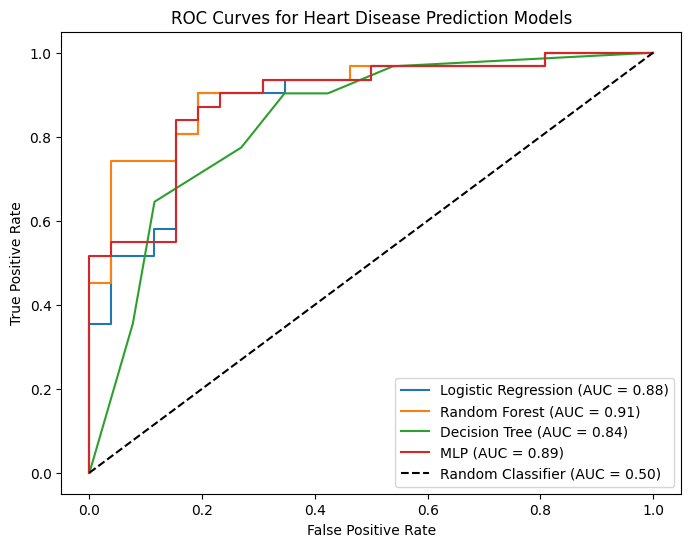

In [27]:
#Membuat ROC Analisis
def plot_roc_curves(y_test, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp):
    plt.figure(figsize=(8, 6))

    # Calculate ROC curves for each model
    fpr_logreg, tpr_logreg, _ = roc_curve(y_test, y_pred_logreg)
    fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf)
    fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_dt)
    fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_pred_mlp)

    # Plot ROC curves
    plt.plot(fpr_logreg, tpr_logreg, label=f'Logistic Regression (AUC = {auc_logreg:.2f})')
    plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})')
    plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.2f})')
    plt.plot(fpr_mlp, tpr_mlp, label=f'MLP (AUC = {auc_mlp:.2f})')

    # Plot random classifier
    plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.50)')

    # Format the plot
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves for Heart Disease Prediction Models')
    plt.legend()
    plt.show()

plot_roc_curves(y_test, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp)

In [28]:
def find_rates_for_thresholds(y_test, y_pred, thresholds):
    fpr_list = []
    tpr_list = []
    for threshold in thresholds:
        y_pred_binary = (y_pred > threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_binary).ravel()
        fpr = fp / (fp + tn)
        tpr = tp / (tp + fn)
        fpr_list.append(fpr)
        tpr_list.append(tpr)
    return fpr_list, tpr_list

thresholds = np.arange(0, 1.1, 0.1)

fpr_logreg, tpr_logreg = find_rates_for_thresholds(y_test, y_pred_logreg, thresholds)
fpr_rf, tpr_rf = find_rates_for_thresholds(y_test, y_pred_rf, thresholds)
fpr_dt, tpr_dt = find_rates_for_thresholds(y_test, y_pred_dt, thresholds)
fpr_mlp, tpr_mlp = find_rates_for_thresholds(y_test, y_pred_mlp, thresholds)


summary_df = pd.DataFrame({
    'Thresholds': thresholds,
    'LogReg_FPR': fpr_logreg,
    'LogReg_TPR': tpr_logreg,
    'RF_FPR': fpr_rf,
    'RF_TPR': tpr_rf,
    'DT_FPR': fpr_dt,
    'DT_TPR': tpr_dt,
    'MLP_FPR': fpr_mlp,
    'MLP_TPR': tpr_mlp
})

display(summary_df)

,Thresholds,LogReg_FPR,LogReg_TPR,RF_FPR,RF_TPR,DT_FPR,DT_TPR,MLP_FPR,MLP_TPR
0,0.0,1.000000,1.000000,0.961538,1.000000,1.000000,1.000000,1.000000,1.000000
1,0.1,0.423077,0.935484,0.615385,0.967742,0.538462,0.967742,0.461538,0.935484
2,0.2,0.346154,0.935484,0.500000,0.967742,0.423077,0.903226,0.346154,0.935484
3,0.3,0.230769,0.903226,0.384615,0.935484,0.423077,0.903226,0.269231,0.903226
4,0.4,0.192308,0.903226,0.230769,0.903226,0.346154,0.903226,0.192308,0.870968
5,0.5,0.192308,0.870968,0.230769,0.903226,0.346154,0.903226,0.192308,0.870968
6,0.6,0.192308,0.838710,0.192308,0.838710,0.346154,0.903226,0.192308,0.838710
7,0.7,0.153846,0.645161,0.076923,0.741935,0.269231,0.774194,0.153846,0.612903
8,0.8,0.115385,0.548387,0.038462,0.483871,0.076923,0.354839,0.115385,0.548387
9,0.9,0.000000,0.322581,0.000000,0.290323,0.076923,0.354839,0.000000,0.258065


In [29]:
def find_best_threshold(y_test, y_pred):
    # based on Youden's Index
    fpr, tpr, thresholds = roc_curve(y_test, y_pred)
    optimal_idx = np.argmax(tpr - fpr)
    return thresholds[optimal_idx]

best_threshold_logreg = find_best_threshold(y_test, y_pred_logreg)
best_threshold_rf = find_best_threshold(y_test, y_pred_rf)
best_threshold_dt = find_best_threshold(y_test, y_pred_dt)
best_threshold_mlp = find_best_threshold(y_test, y_pred_mlp)

print(f"Best threshold for Logistic Regression: {best_threshold_logreg}")
print(f"Best threshold for Random Forest: {best_threshold_rf}")
print(f"Best threshold for Decision Tree: {best_threshold_dt}")
print(f"Best threshold for MLP: {best_threshold_mlp}")

Best threshold for Logistic Regression: 0.4224259666386716
Best threshold for Random Forest: 0.5821832611832609
Best threshold for Decision Tree: 0.6086956521739131
Best threshold for MLP: 0.6187029422231092


In [30]:
# Membuat dictionary yang berisi model dan scaler
artifacts = {
    'best_model': fit_clf_rf,
    'scaler': scaler
}

# Menyimpan dictionary ke dalam file pickle
pkl_filename = 'heart_disease_artifacts.pkl'
with open(pkl_filename, 'wb') as file:
    pickle.dump(artifacts, file)

print(f"Model dan scaler telah disimpan ke dalam file: {pkl_filename}")

Model dan scaler telah disimpan ke dalam file: heart_disease_artifacts.pkl
